In [1]:
import torch
import numpy as np
import networkx as nx
import os, sys

In [2]:
path_to_root = os.path.abspath(os.path.join('..'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)
    

In [3]:
from geom_hyp import lorentz as L
from geom_hyp import manifold_conversion as MC
from geom_hyp import poincare, hyperboloid
import geom_hyp.pmath as pmath

In [4]:
from label_details import get_hierarchy

data_track =  "ISIC 2019 datasets" #  "MILK 10k Datasets", "Derm12345 datasets", "ISIC 2019 datasets"

TREE, NODES, CLASS_COLS = get_hierarchy("isic2019") # milk10k, isic2019, derm12345

In [5]:
print("Hierarchy edges + ", data_track)

stage_scale = [0, 1, 1, 1]  # deeper levels reuse the last value


def get_scale(depth):
    return stage_scale[min(depth, len(stage_scale) - 1)]


def build_edges(tree):
    edges = []

    def traverse(parent, children, parent_depth):
        if isinstance(children, dict):
            for child, descendants in children.items():
                child_depth = parent_depth + 1
                edges.append((parent, child, get_scale(child_depth)))
                traverse(child, descendants, child_depth)

        elif isinstance(children, (list, tuple)):
            leaf_depth = parent_depth + 1
            edges.extend(
                (parent, leaf, get_scale(leaf_depth))
                for leaf in children
            )

        else:
            raise TypeError(
                f"Children of '{parent}' must be a dict, list, or tuple; "
                f"received {type(children).__name__}"
            )

    for root, children in tree.items():
        traverse(root, children, parent_depth=0)

    return edges


EDGES_RAW = build_edges(TREE)

Hierarchy edges +  ISIC 2019 datasets


In [6]:
print(data_track + ' Node Ordering')
# Validate node ordering
if len(NODES) != len(set(NODES)):
    raise ValueError("NODES contains duplicate names")

node_to_idx = {node: idx for idx, node in enumerate(NODES)}
idx_to_node = {idx: node for node, idx in node_to_idx.items()}

# Check that every edge node exists in NODES
edge_nodes = {
    node
    for parent, child, _ in EDGES_RAW
    for node in (parent, child)
}
missing_nodes = edge_nodes - set(NODES)

if missing_nodes:
    raise ValueError(f"Nodes missing from NODES: {sorted(missing_nodes)}")

# Convert named edges to indexed edges
EDGES = [
    (node_to_idx[parent], node_to_idx[child], scale)
    for parent, child, scale in EDGES_RAW
]

# Determine node depths from the edges
node_depth = {"root": 0}
remaining = list(EDGES_RAW)

while remaining:
    next_remaining = []

    for parent, child, scale in remaining:
        if parent in node_depth:
            node_depth[child] = node_depth[parent] + 1
        else:
            next_remaining.append((parent, child, scale))

    if len(next_remaining) == len(remaining):
        raise ValueError("Disconnected nodes or invalid tree structure")

    remaining = next_remaining

# Count nodes at each depth
depth_counts = {}
for node, depth in node_depth.items():
    depth_counts[depth] = depth_counts.get(depth, 0) + 1

print("node_to_idx:", node_to_idx)
print("\nEdges:", EDGES)
print("\nNum nodes:", len(NODES))
print("Num leaf classes:", len(CLASS_COLS))

for depth in sorted(depth_counts):
    print(f"Num nodes at depth {depth}: {depth_counts[depth]}")

print("Num edges:", len(EDGES))

ISIC 2019 datasets Node Ordering
node_to_idx: {'MEL': 0, 'NV': 1, 'BCC': 2, 'AK': 3, 'BKL': 4, 'DF': 5, 'VASC': 6, 'SCC': 7, 'UNK': 8, 'melanocytic_benign': 9, 'keratinocytic_benign': 10, 'fibrohistiocytic_benign': 11, 'vascular_benign': 12, 'keratinocytic_precancer': 13, 'melanocytic_malignant': 14, 'keratinocytic_malignant': 15, 'benign': 16, 'premalignant': 17, 'malignant': 18, 'unknown': 19, 'root': 20}

Edges: [(20, 16, 1), (16, 9, 1), (9, 1, 1), (16, 10, 1), (10, 4, 1), (16, 11, 1), (11, 5, 1), (16, 12, 1), (12, 6, 1), (20, 17, 1), (17, 13, 1), (13, 3, 1), (20, 18, 1), (18, 14, 1), (14, 0, 1), (18, 15, 1), (15, 2, 1), (15, 7, 1), (20, 19, 1), (19, 8, 1)]

Num nodes: 21
Num leaf classes: 9
Num nodes at depth 0: 1
Num nodes at depth 1: 4
Num nodes at depth 2: 8
Num nodes at depth 3: 8
Num edges: 20


In [7]:
print("Common route for all datasets: currently: ", data_track)

import networkx as nx
import matplotlib.pyplot as plt

def graph_from_raw_edges(edges_raw, nodes=None, root="root"):
    """Build and validate a directed hierarchy from raw weighted edges."""
    G = nx.DiGraph()
    G.add_weighted_edges_from(edges_raw)
    # Preserve isolated nodes if NODES is provided
    if nodes is not None:
        G.add_nodes_from(nodes)
    if root not in G:
        raise ValueError(f"Root '{root}' is not present in the graph")
    if not nx.is_arborescence(G):
        raise ValueError(
            "EDGES_RAW must define one connected, directed tree "
            "with one parent per non-root node"
        )
    # Assign depth to every node
    depths = nx.single_source_shortest_path_length(G, root)
    nx.set_node_attributes(G, depths, "depth")
    return G

G = graph_from_raw_edges(
    EDGES_RAW,
    nodes=NODES,
    root="root",)

# Node groups
root = "root"
leaf_nodes = [node for node in G if G.out_degree(node) == 0]
internal_nodes = [
    node for node in G
    if node != root and G.out_degree(node) > 0]

print("Num nodes:", G.number_of_nodes())
print("Num edges:", G.number_of_edges())
print("Num leaf nodes:", len(leaf_nodes))
print("Num internal nodes:", len(internal_nodes))
# Count nodes at each depth
depth_counts = {}
for depth in nx.get_node_attributes(G, "depth").values():
    depth_counts[depth] = depth_counts.get(depth, 0) + 1

for depth, count in sorted(depth_counts.items()):
    print(f"Depth {depth}: {count} nodes")

Common route for all datasets: currently:  ISIC 2019 datasets
Num nodes: 21
Num edges: 20
Num leaf nodes: 9
Num internal nodes: 11
Depth 0: 1 nodes
Depth 1: 4 nodes
Depth 2: 8 nodes
Depth 3: 8 nodes


In [8]:
def radial_tree_layout(G, root="root", radius_step=1.8):
    """Place the root at the center and each depth on a circular ring."""

    leaf_count = {}

    def count_leaves(node):
        children = list(G.successors(node))
        leaf_count[node] = (
            1 if not children
            else sum(count_leaves(child) for child in children)
        )
        return leaf_count[node]

    count_leaves(root)
    pos, angles = {root: (0, 0)}, {root: 0}

    def place(node, start, end, depth):
        children = list(G.successors(node))
        current = start

        for child in children:
            width = (end - start) * leaf_count[child] / leaf_count[node]
            theta = current + width / 2
            radius = depth * radius_step

            pos[child] = radius * np.array([np.cos(theta), np.sin(theta)])
            angles[child] = theta

            place(child, current, current + width, depth + 1)
            current += width

    place(root, 0, 2 * np.pi, 1)
    return pos, angles

    
def plot_tree_visual(G, root=None, title="Dataset Class Hierarchy"):
    if not G.is_directed():
        raise TypeError("Radial hierarchy visualization requires a directed graph")

    # Infer root for either named or indexed graphs
    roots = [node for node in G if G.in_degree(node) == 0]
    if root is None:
        if len(roots) != 1:
            raise ValueError(f"Expected one root, found {roots}")
        root = roots[0]

    if root not in G:
        raise ValueError(f"Root {root!r} is not present in the graph")

    leaf_nodes = [n for n in G if G.out_degree(n) == 0]
    internal_nodes = [
        n for n in G
        if n != root and G.out_degree(n) > 0
    ]

    # Compute depths locally
    depths = nx.single_source_shortest_path_length(G, root)
    nx.set_node_attributes(G, depths, "depth")

    pos, angles = radial_tree_layout(G, root)
    fig, ax = plt.subplots(figsize=(14, 14))

    # Depth rings
    for depth in range(1, max(depths.values()) + 1):
        ax.add_patch(
            plt.Circle(
                (0, 0),
                depth * 1.8,
                fill=False,
                color="lightgray",
                linewidth=0.7,
                linestyle="--",
            )
        )

    nx.draw_networkx_edges(
        G, pos,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=10,
        edge_color="gray",
        width=1,
        alpha=0.65,
        ax=ax,
    )

    for nodes, color, size in [
        ([root], "tomato", 1500),
        (internal_nodes, "skyblue", 900),
        (leaf_nodes, "lightgreen", 450),
    ]:
        nx.draw_networkx_nodes(
            G, pos,
            nodelist=nodes,
            node_color=color,
            node_size=size,
            ax=ax,
        )

    nx.draw_networkx_labels(
        G,
        pos,
        labels={n: str(n) for n in [root] + internal_nodes},
        font_size=7,
        ax=ax,
    )

    # Rotated leaf labels
    for node in leaf_nodes:
        x, y = pos[node]
        angle = np.degrees(angles[node])
        right_side = np.cos(angles[node]) >= 0

        ax.annotate(
            str(node),
            (x, y),
            xytext=(6 if right_side else -6, 0),
            textcoords="offset points",
            rotation=angle if right_side else angle + 180,
            rotation_mode="anchor",
            ha="left" if right_side else "right",
            va="center",
            fontsize=7,
        )

    ax.set_title(title, fontsize=16)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

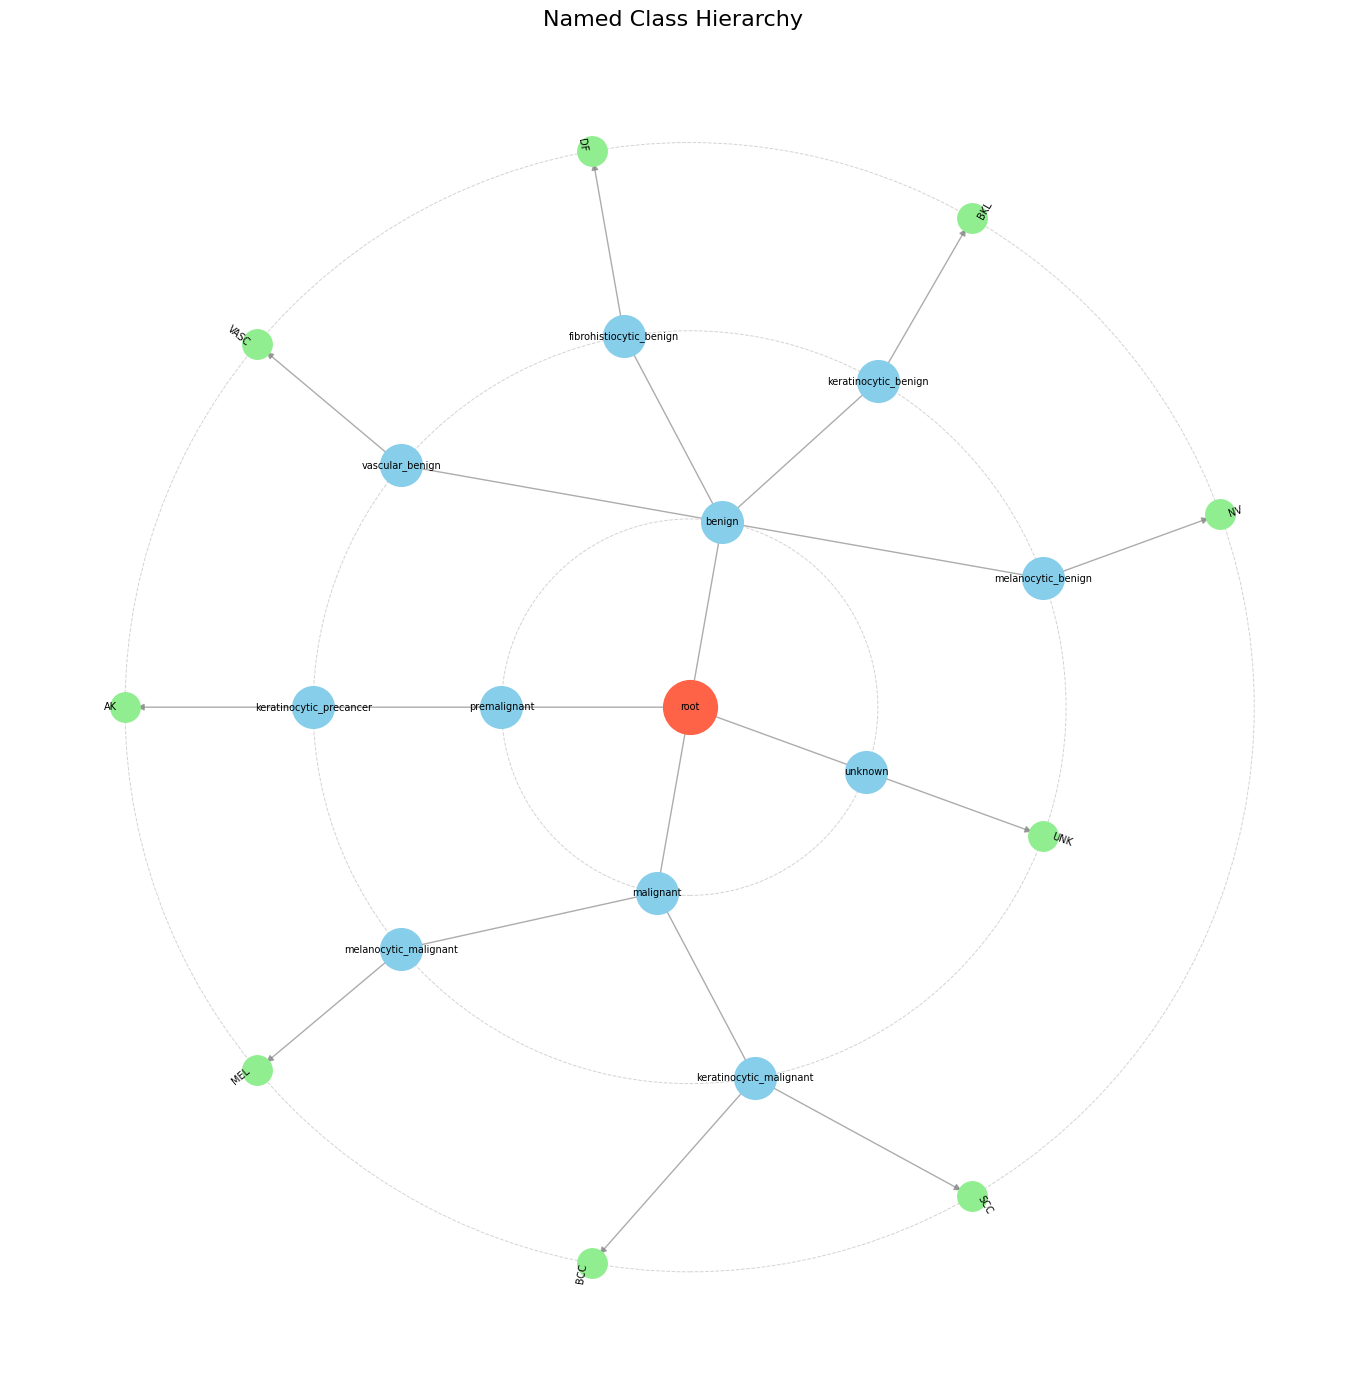

In [9]:
# plot Helper
import numpy as np
plot_tree_visual(G, title="Named Class Hierarchy")


BUILD G_idx graph
Named nodes: ['root', 'benign', 'melanocytic_benign', 'NV', 'keratinocytic_benign', 'BKL', 'fibrohistiocytic_benign', 'DF', 'vascular_benign', 'VASC', 'premalignant', 'keratinocytic_precancer', 'AK', 'malignant', 'melanocytic_malignant', 'MEL', 'keratinocytic_malignant', 'BCC', 'SCC', 'unknown', 'UNK']
Indexed nodes: [20, 16, 9, 1, 10, 4, 11, 5, 12, 6, 17, 13, 3, 18, 14, 0, 15, 2, 7, 19, 8]
Indexed edges: [(20, 16, {'weight': 1}), (20, 17, {'weight': 1}), (20, 18, {'weight': 1}), (20, 19, {'weight': 1}), (16, 9, {'weight': 1}), (16, 10, {'weight': 1}), (16, 11, {'weight': 1}), (16, 12, {'weight': 1}), (9, 1, {'weight': 1}), (10, 4, {'weight': 1}), (11, 5, {'weight': 1}), (12, 6, {'weight': 1}), (17, 13, {'weight': 1}), (13, 3, {'weight': 1}), (18, 14, {'weight': 1}), (18, 15, {'weight': 1}), (14, 0, {'weight': 1}), (15, 2, {'weight': 1}), (15, 7, {'weight': 1}), (19, 8, {'weight': 1})]


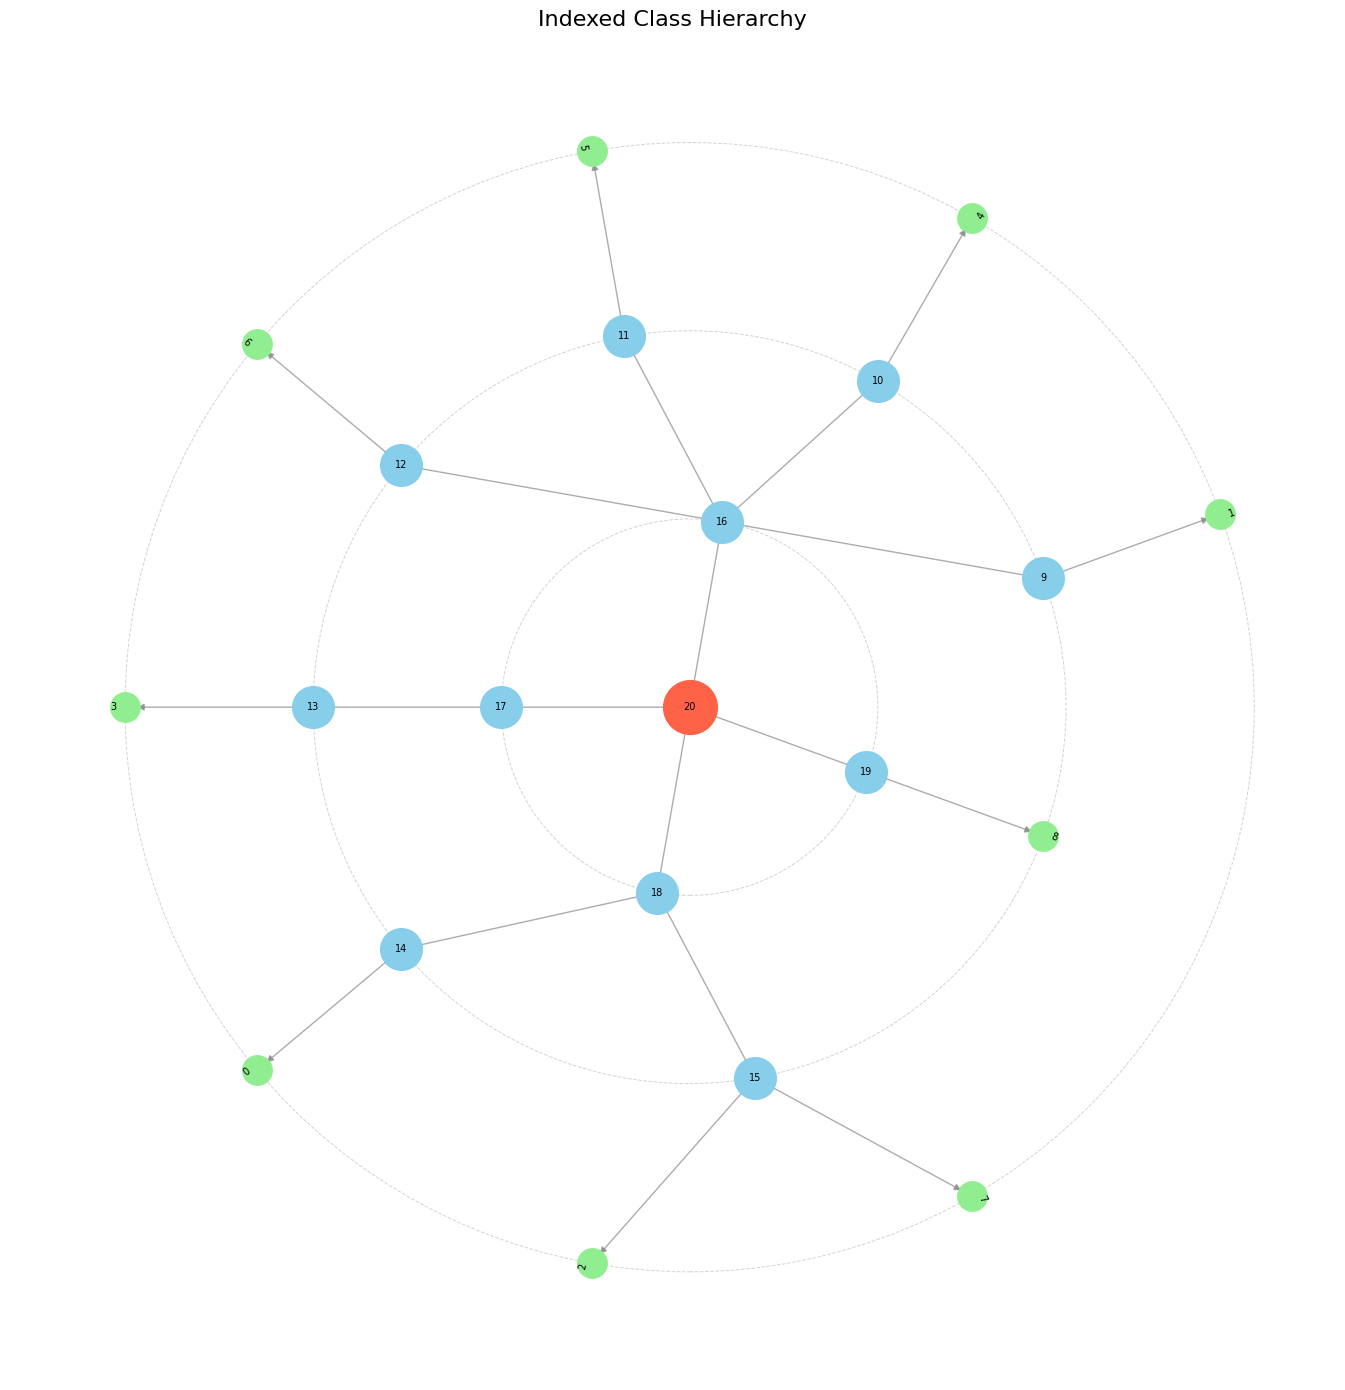

In [10]:
# ==========================================
# Original node names
# ==========================================
print("BUILD G_idx graph")
nodes = NODES
G_idx = nx.relabel_nodes(G, node_to_idx, copy=True) # Building G_idx

print("Named nodes:", list(G.nodes()))
print("Indexed nodes:", list(G_idx.nodes()))
print("Indexed edges:", list(G_idx.edges(data=True)))


plot_tree_visual(G_idx, title="Indexed Class Hierarchy")

In [11]:
# list(G_idx.edges(data=True))[0] # getting all the pairs
# directed tree validation
depth = nx.get_node_attributes(G_idx, "depth")

assert all(
    depth[parent] + 1 == depth[child]
    for parent, child in G_idx.edges()
)

print("All edges follow parent -> child")
assert isinstance(G_idx, nx.DiGraph)
assert nx.is_arborescence(G_idx)

roots = [n for n in G_idx if G_idx.in_degree(n) == 0]
assert len(roots) == 1

for parent, child in G_idx.edges():
    assert G_idx.in_degree(child) == 1
    assert depth[child] == depth[parent] + 1

print("Valid directed tree: every edge is parent -> child")

All edges follow parent -> child
Valid directed tree: every edge is parent -> child


In [12]:
# import sarkar_embedding_wt as sarkar_embed
# import importlib
# importlib.reload(sarkar_embed)
from sarkar_embedding_wt import sarkar, gen_sarkar

In [14]:
# general sarkar construction
dim = 64
stage_scale =  [0, 0.6, 0.5, 0.5 ]
z = gen_sarkar(G_idx, tau = 3/3, root = len(NODES)-1, dim= dim, stage_scale = stage_scale, coding= False) # coding false super important
# can learn general prototypes
result = {
    "setting": {
        "tau": 2,
        "root": 14,
        "dim": 64,
    },
    "data": torch.from_numpy(z).float() # torch.tensor(z).float()
}

# z = sarkar(G_idx, tau = 1/3, root = 60, dim= 64) # sarkers code
# # can learn general prototypes 
# result = {
#     "setting": {
#         "tau": 2,
#         "root": 14,
#         "dim": 32,
#     },
#     "data": torch.from_numpy(z).float() # torch.tensor(z).float()
# }

z_t = torch.from_numpy(z).float()


In [16]:
def poincare_distance(x, y, c=1.0, eps=None):
    """
    Poincaré distance with curvature -c.
    Args:
        x, y: Tensors [..., D] inside the ball ||x|| < 1/sqrt(c).
        c:    Positive curvature magnitude.
    Returns:
        Distances with shape [...].
    """
    if c <= 0:
        raise ValueError("c must be positive")
    eps = eps or torch.finfo(x.dtype).eps
    x2 = x.square().sum(dim=-1)
    y2 = y.square().sum(dim=-1)
    xy2 = (x - y).square().sum(dim=-1)
    denominator = (
        (1 - c * x2) * (1 - c * y2)
    ).clamp_min(eps)
    acosh_input = (
        1 + 2 * c * xy2 / denominator
    ).clamp_min(1 + eps)
    return torch.acosh(acosh_input) / (c ** 0.5)

In [17]:
max_val = 0
for i in range(9):
    cur_val = poincare_distance(z_t[len(NODES)-1], z_t[i])
    # print(cur_val)
    if max_val < cur_val:
        max_val = cur_val



poincare_distance(z_t[:40], z_t[-1])

tensor([0.9198, 1.0170, 1.0535, 0.9294, 1.0445, 0.8936, 0.9859, 0.9998, 1.0354,
        0.9332, 0.9435, 1.0355, 1.0454, 0.9494, 0.9081, 1.0002, 1.0029, 0.9000,
        1.0673, 0.9781, 0.9043, 1.0213, 1.0317, 0.9473, 1.0148, 0.9844, 0.9203,
        1.0093, 0.8385, 0.9690, 0.9882, 0.9808, 0.9175, 0.9294, 0.9615, 1.0593,
        0.9533, 0.8686, 1.0867, 0.8922])

In [14]:
# similarity analysis
z_l = MC.poincare_to_lorentz(z_t)[:,1:]
mini = L.pairwise_dist(z_l[0:9], z_l[0:9])
x_masked = mini.clone()
x_masked.fill_diagonal_(float("inf"))

min_val = x_masked.min()
idx = torch.argwhere(x_masked == min_val)[0]

print(min_val)
print(idx)  # tensor([row, col])
min_vals, min_indices = x_masked.min(dim=1)
min_indices

def topk_similar(dist_matrix, k=4):
    """
    dist_matrix: [N, N] symmetric distance matrix

    returns:
        values:  [N, k] distances of k most similar items
        indices: [N, k] indices of k most similar items
    """
    dist = dist_matrix.clone()
    dist.fill_diagonal_(float("inf"))  # exclude self

    values, indices = torch.topk(
        dist, k=k, dim=1, largest=False
    )

    return values, indices

v, i = topk_similar(mini)
print(v[3],i[3])

tensor(0.6692)
tensor([5, 7])
tensor([1.0942, 1.1002, 1.1004, 1.3102]) tensor([0, 2, 1, 5])


In [24]:
import torch.nn.functional as F
F.softmax(torch.tensor([0.6614, 1.3368, 1.1458, 1.3086, 1.0898, 1.2454, 1.4670, 0.9516, 0.8958,
        0.8724, 2.0795, 0.1])/2* -6)

/scratch/26247848/ipykernel_3065087/3339235021.py:2: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  F.softmax(torch.tensor([0.6614, 1.3368, 1.1458, 1.3086, 1.0898, 1.2454, 1.4670, 0.9516, 0.8958,


tensor([0.1124, 0.0148, 0.0263, 0.0161, 0.0311, 0.0195, 0.0100, 0.0471, 0.0556,
        0.0597, 0.0016, 0.6057])

In [99]:
def average_distortion(
    G_idx,
    z,
    distance_fn,
    weighted=False,
    batch_size=4096,
):
    """
    Args:
        G_idx:       NetworkX graph with integer nodes 0,...,N-1.
        z:           Tensor [N, D], where z[i] is node i's embedding.
        distance_fn: distance_fn(x, y) -> tensor [B].
        weighted:    Use graph edge weights for tree distance.
        batch_size:  Number of node pairs processed simultaneously.

    Returns:
        Scalar tensor containing average distortion.
    """
    n = z.shape[0]

    if set(G_idx.nodes) != set(range(n)):
        raise ValueError("G_idx nodes must be integers 0,...,N-1")

    # Tree distance is undirected
    G_tree = G_idx.to_undirected()
    weight = "weight" if weighted else None

    if not nx.is_connected(G_tree):
        raise ValueError("G_idx must be connected")

    # All-pairs tree distances
    d_tree = torch.as_tensor(
        nx.floyd_warshall_numpy(
            G_tree,
            nodelist=range(n),
            weight=weight,
        ),
        dtype=z.dtype,
        device=z.device,
    )

    # Unique unordered pairs: u < v
    u, v = torch.triu_indices(
        n,
        n,
        offset=1,
        device=z.device,
    )

    distortion_sum = z.new_zeros(())

    for start in range(0, u.numel(), batch_size):
        u_batch = u[start:start + batch_size]
        v_batch = v[start:start + batch_size]

        d_embedding = distance_fn(
            z[u_batch],
            z[v_batch],
        ).reshape(-1)

        d_target = d_tree[u_batch, v_batch]

        if d_embedding.numel() != d_target.numel():
            raise ValueError(
                "distance_fn must return one distance per node pair"
            )

        relative_error = (
            (d_embedding - d_target).abs() / d_target
        )
        distortion_sum += relative_error.sum()

    return distortion_sum / u.numel()

In [124]:

D_ave = average_distortion(
    G_idx,
    z_t,
    distance_fn=poincare_distance,
    weighted=False,
)

print("Average distortion:", D_ave.item())

Average distortion: 0.4706695079803467


In [18]:
# saving 
torch.save(result, "sarker_embedding" + data_track + "_64_small_radius.pt")

In [13]:
# check loading

results = torch.load("sarker_embeddingDerm12345 datasets_64_small_radius.pt")

z_t = results["data"]  # torch.Tensor, lorentz
print(type(z))
print(z.shape)

/scratch/26255453/ipykernel_1689848/1946265429.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  results = torch.load("sarker_embeddingDerm12345 datasets_64_small_radius.p

NameError: name 'z' is not defined

In [15]:
z_t = torch.tensor(z).float()
z_t.pow(2).sum(-1).sqrt()

tensor([0.9305, 0.9356, 0.9267, 0.9330, 0.9316, 0.9484, 0.9311, 0.9340, 0.9355,
        0.8960, 0.8932, 0.7616, 0.7616, 0.7616, 0.0000])

In [17]:
MC.poincare_to_lorentz(z_t)[:, :1]

tensor([[13.9151],
        [15.0493],
        [13.1568],
        [14.4472],
        [14.1274],
        [18.8751],
        [14.0325],
        [14.6762],
        [15.0269],
        [ 9.1413],
        [ 8.8901],
        [ 3.7622],
        [ 3.7622],
        [ 3.7622],
        [ 1.0000]])

In [5]:
# Numerical stability checking
# DOES THE feature clipping needs to be same on poincare/lorentz
def clip(input_vector, r):
    input_norm = torch.norm(input_vector, dim = -1)
    clip_value = float(r)/input_norm
    min_norm = torch.clamp(float(r)/input_norm, max = 1)
    return min_norm[:, None] * input_vector


v = torch.rand(32, 32)*30
vc = clip(v, 3.7)
print(torch.tanh(vc.norm(2, -1)/2)) # remember the division 2 formulation

tensor([0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517])


In [ ]:
MC.poincare_to_lorentz(z_l)[:, :1]
MC.spatial_to_lorentz(L.exp_map0(vc))[:,:1]

In [36]:
print(L.exp_map0(vc))
import math
(MC.lorentz_to_poincare(MC.spatial_to_lorentz(L.exp_map0(vc)))).norm(2,-1)

tensor([[1.9958, 0.9091, 5.9758,  ..., 5.2582, 2.9261, 1.7566],
        [4.7272, 2.3031, 0.8864,  ..., 3.2754, 5.7836, 5.3900],
        [3.1734, 0.9833, 1.5688,  ..., 3.1121, 1.3978, 1.3622],
        ...,
        [3.0196, 1.3999, 3.0851,  ..., 2.3249, 3.4318, 2.4690],
        [1.1707, 1.5486, 4.8841,  ..., 3.6696, 0.0492, 3.8554],
        [5.6191, 1.5962, 2.6106,  ..., 1.5181, 2.4471, 1.0992]])


tensor([0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517])

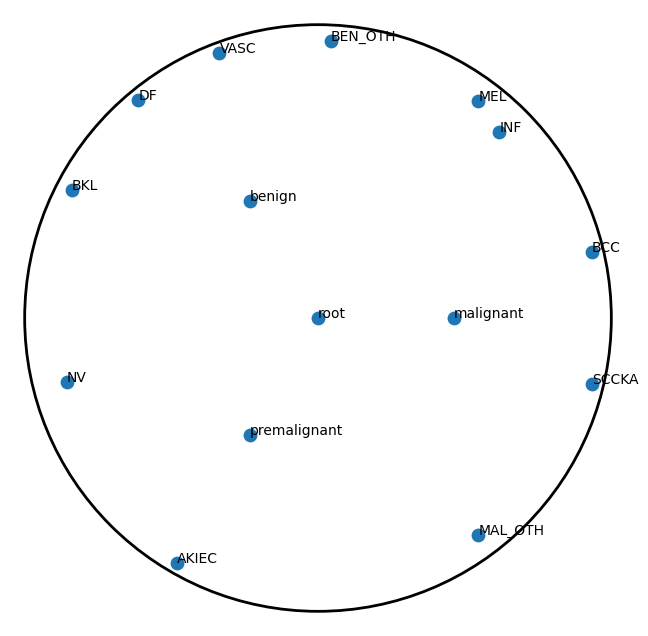

In [23]:

# =========================================================
# Optional labels
# =========================================================

labels = NODES

fig, ax = plt.subplots(figsize=(8, 8))

# -----------------------------------------
# Poincaré disk boundary
# -----------------------------------------
circle = plt.Circle(
    (0, 0),
    1.0,
    fill=False,
    linewidth=2
)
ax.add_artist(circle)
# -----------------------------------------
# Scatter points
# -----------------------------------------
ax.scatter(
    z[:, 0],
    z[:, 1],
    s=80
)
# -----------------------------------------
# Labels
# -----------------------------------------
for i, txt in enumerate(labels):

    ax.annotate(
        txt,
        (z[i, 0], z[i, 1]),
        fontsize=10
    )


ax.set_aspect("equal")
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
ax.axis("off")
plt.show()

In [24]:
import pandas as pd

df = pd.read_csv("DERM12345/derm12345_supplemental.csv")

print(len(df["label"].unique()))
print(sorted(df["label"].unique()))

40
['acb', 'acd', 'ajb', 'ajd', 'ak', 'alm', 'angk', 'anm', 'bcc', 'bd', 'bdb', 'cb', 'ccb', 'ccd', 'cd', 'ch', 'cjb', 'db', 'df', 'dfsp', 'ha', 'isl', 'jb', 'jd', 'ks', 'la', 'lk', 'lm', 'lmm', 'ls', 'mcb', 'mel', 'mpd', 'pg', 'rd', 'sa', 'scc', 'sk', 'sl', 'srjd']


In [22]:
import numpy as np
from scipy.spatial.distance import squareform
import networkx as nx

classes = nodes
n = len(classes)

D = np.zeros((n, n), dtype=np.float32)

for i, a in enumerate(classes):
    for j, b in enumerate(classes):

        if i == j:
            D[i, j] = 0
        else:
            D[i, j] = nx.shortest_path_length(
                G,
                source=a,
                target=b,
                weight="weight"
            )

# =========================================================
# Condensed upper-triangle vector
# (same format as your mammals example)
# =========================================================

compressed_metric = squareform(D)

print("Labels:")
print(labels)

print("\nDistance Matrix:")
print(D)

print("\nCompressed Metric:")
print(compressed_metric)

Labels:
['AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC', 'benign', 'premalignant', 'malignant', 'root']

Distance Matrix:
[[  0. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 250.  50. 250.
  150.]
 [300.   0. 300. 300. 300. 300. 100. 100. 300. 100. 300. 250. 250.  50.
  150.]
 [300. 300.   0. 100. 100. 100. 300. 300. 100. 300. 100.  50. 250. 250.
  150.]
 [300. 300. 100.   0. 100. 100. 300. 300. 100. 300. 100.  50. 250. 250.
  150.]
 [300. 300. 100. 100.   0. 100. 300. 300. 100. 300. 100.  50. 250. 250.
  150.]
 [300. 300. 100. 100. 100.   0. 300. 300. 100. 300. 100.  50. 250. 250.
  150.]
 [300. 100. 300. 300. 300. 300.   0. 100. 300. 100. 300. 250. 250.  50.
  150.]
 [300. 100. 300. 300. 300. 300. 100.   0. 300. 100. 300. 250. 250.  50.
  150.]
 [300. 300. 100. 100. 100. 100. 300. 300.   0. 300. 100.  50. 250. 250.
  150.]
 [300. 100. 300. 300. 300. 300. 100. 100. 300.   0. 300. 250. 250.  50.
  150.]
 [300. 300. 100. 100. 100. 100. 300. 3

In [6]:
print('CPCC data preparation begins here')
from label_details import get_hierarchy

data_track =  "Derm12345 datasets" #  "MILK 10k Datasets", "Derm12345 datasets", "ISIC 2019 datasets"

dataset_name = "DERM12345_h"  # isic2019_h, DERM12345_h, MILK_10K

TREE, NODES, CLASS_COLS = get_hierarchy("derm12345") # milk10k, isic2019, derm12345

CPCC data preparation begins here


In [7]:
# =========================================================
# Node name -> node ID
# =========================================================

name2wnid = {
    name: str(idx)
    for idx, name in enumerate(NODES)
}
# =========================================================
# Leaf/class name -> training label ID
# Exact ordering follows CLASS_COLS
# =========================================================
leaf2labelid = {
    leaf: idx
    for idx, leaf in enumerate(CLASS_COLS)
}
# =========================================================
# Recursively extract parent -> child edges from TREE
# =========================================================


weights = [0, 0.8, 0.8, 0.9 ]   # root, level 1, level 2
# weights = None        # no weighted hierarchy


edges = []

def extract_edges(tree, depth=0):
    for parent, children in tree.items():

        if isinstance(children, dict):

            for child in children.keys():

                if weights is None:
                    edges.append((
                        int(name2wnid[parent]),
                        int(name2wnid[child])
                    ))
                else:
                    edges.append((
                        int(name2wnid[parent]),
                        int(name2wnid[child]),
                        weights[depth + 1]
                    ))

            extract_edges(children, depth + 1)

        elif isinstance(children, list):

            for child in children:

                if weights is None:
                    edges.append((
                        int(name2wnid[parent]),
                        int(name2wnid[child])
                    ))
                else:
                    edges.append((
                        int(name2wnid[parent]),
                        int(name2wnid[child]),
                        weights[depth + 1]
                    ))

extract_edges(TREE)
# =========================================================
# Original/training class information
# =========================================================
data_class_info = [
    [
        leaf2labelid[leaf],
        name2wnid[leaf],
        leaf
    ]
    for leaf in CLASS_COLS
]

In [ ]:
dataset_name
data_class_info

In [22]:
# required saving for the CPCC application
import json

with open(f"{dataset_name}/class_hierarchy_w.txt", "w") as file:
    for edge in edges:
        if len(edge) == 2:
            id1, id2 = edge
            file.write(f"{id1} {id2}\n")

        else:
            id1, id2, weight = edge
            file.write(f"{id1} {id2} {weight}\n")


with open(f"{dataset_name}/dataset_class_info.json", "w") as file:

    json.dump(data_class_info, file)


with open(f"{dataset_name}/node_names.txt", "w") as file:

    for idx, name in enumerate(NODES):

        file.write(f"{idx}\t{name}\n")

In [8]:
import importlib
import Datasets.hierarchy_data.data_hierarchy as dh
importlib.reload(dh)


<module 'Datasets.hierarchy_data.data_hierarchy' from '/user/zahidhas/FM_Skin_Cancer/SkinFM_med/Datasets/hierarchy_data/data_hierarchy.py'>

In [24]:
data_hierarchy= dh.Hierarchy(dataset_name, "") 

FileNotFoundError: [Errno 2] No such file or directory: 'DERM12345_h/class_hierarchy.txt'

In [9]:
data_hierarchy_w =  dh.Hierarchy_W(dataset_name, "") 

In [9]:
TREE, NODES, CLASS_COLS

data_hierarchy_zh =  dh.Hierarchy_ZH( CLASS_COLS,TREE, NODES, weights) 

In [ ]:
data_hierarchy_zh.tree_dist

In [ ]:
data_hierarchy_w.tree_dist

In [10]:
data_hierarchy_w.label_map[:,0]

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23',
       '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34',
       '35', '36', '37', '38', '39'], dtype=object)

In [ ]:
data_hierarchy_w.LEAF_IDS

In [13]:
from hierarchy_data.cpcc_losses import CPCCLoss

In [14]:
from types import SimpleNamespace

args = SimpleNamespace(
    cpcc=1,
    cpcc_metric="poincare_mean",   # "l2", "l1", "poincare", or "poincare_exp_c", poincare_mean, lorentz_mean
    leaf_only=0,
    lamb=1.0,
    center=0,

    poincare_low_dim_project=0,
    poincare_head_dim=512,
    hyp_c=1.0,
    clip_r=2.3,
    train_c=False,
    feature_dim=512,

    num_workers=12,
    batch_size=512,
    seeds=5,

    warm=False,
    temp=0.1,
    normalize=0,

    bottleneck=True,
    augment=True,
    local_rank=0,
    encoder_manifold="euclidean",
)

In [15]:
args.cpcc_metric

'poincare_mean'

In [16]:
# criterion_cpcc = CPCCLoss(data_hierarchy, args)
# criterion_cpcc = CPCCLoss(data_hierarchy_w, args)
criterion_cpcc = CPCCLoss(data_hierarchy_zh, args)

In [17]:
representations = vc
loss_cpcc = criterion_cpcc(representations, targets_fine)
loss_cpcc

NameError: name 'targets_fine' is not defined

In [ ]:
criterion_cpcc.tree_dist

In [18]:
batch_size = 32

v = torch.rand(batch_size, 32)*2
vc = clip(v,3.7).to(torch.float64)


targets_fine = torch.randint(low=0, high=39, size=(batch_size,))
print(torch.tanh(vc.norm(2, -1)/2))

tensor([0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517, 0.9517,
        0.9517, 0.9517, 0.9517, 0.9517, 0.9517], dtype=torch.float64)


In [104]:
vc

tensor([[0.3603, 0.4010, 0.7981,  ..., 0.1493, 0.9922, 0.4898],
        [0.1817, 0.7941, 1.0350,  ..., 1.0156, 0.6217, 0.8481],
        [0.8424, 0.3350, 0.5357,  ..., 0.3005, 0.4497, 0.9657],
        ...,
        [0.1880, 0.2085, 0.3563,  ..., 0.2544, 0.8927, 0.4330],
        [0.3126, 0.1414, 0.8313,  ..., 0.1183, 1.0224, 0.5268],
        [0.7817, 0.9315, 1.0672,  ..., 0.2662, 0.4779, 0.5357]],
       dtype=torch.float64)

In [105]:
# now generates identical: considering the tanh(norm/2) equation. 
pc = MC.lorentz_to_poincare(MC.spatial_to_lorentz(L.exp_map0(vc)))
pc2 = poincare.expmap0(vc) # easy single step tanh(norm/2) # modified in the expmap0 eq. 

In [20]:
# cpcc forward analysis
label_map = torch.tensor(criterion_cpcc.label_map_int, device=targets_fine.device)
label_map[targets_fine]

tensor([[10, 11, 12,  3],
        [57, 21, 22,  3],
        [29,  5,  2,  3],
        [29,  5,  2,  3],
        [ 8,  9,  2,  3],
        [33, 34, 18,  3],
        [ 4,  5,  2,  3],
        [51, 14, 15,  3],
        [30, 21, 22,  3],
        [49, 39,  2,  3],
        [35, 36, 22,  3],
        [24, 25,  2,  3],
        [50,  1,  2,  3],
        [48, 14, 15,  3],
        [45, 46, 18,  3],
        [ 6,  7,  2,  3],
        [41,  9,  2,  3],
        [28,  5,  2,  3],
        [37, 17, 18,  3],
        [47, 14, 15,  3],
        [10, 11, 12,  3],
        [45, 46, 18,  3],
        [26,  1,  2,  3],
        [31,  7,  2,  3],
        [20, 21, 22,  3],
        [50,  1,  2,  3],
        [38, 39,  2,  3],
        [51, 14, 15,  3],
        [38, 39,  2,  3],
        [53, 17, 18,  3],
        [56, 17, 18,  3],
        [59, 39,  2,  3]])

In [21]:
print(criterion_cpcc.label_map_int)
criterion_cpcc.label_map_str
criterion_cpcc.str2int

[[ 0  1  2  3]
 [ 4  5  2  3]
 [ 6  7  2  3]
 [ 8  9  2  3]
 [10 11 12  3]
 [13 14 15  3]
 [16 17 18  3]
 [19 14 15  3]
 [20 21 22  3]
 [23 21 22  3]
 [24 25  2  3]
 [26  1  2  3]
 [27  1  2  3]
 [28  5  2  3]
 [29  5  2  3]
 [30 21 22  3]
 [31  7  2  3]
 [32 25  2  3]
 [33 34 18  3]
 [35 36 22  3]
 [37 17 18  3]
 [38 39  2  3]
 [40  7  2  3]
 [41  9  2  3]
 [42 43 22  3]
 [44 17 18  3]
 [45 46 18  3]
 [47 14 15  3]
 [48 14 15  3]
 [49 39  2  3]
 [50  1  2  3]
 [51 14 15  3]
 [52 21 22  3]
 [53 17 18  3]
 [54 55  2  3]
 [56 17 18  3]
 [57 21 22  3]
 [58 46 18  3]
 [59 39  2  3]
 [60  9  2  3]]


{'0': 0,
 '40': 1,
 '55': 2,
 '60': 3,
 '1': 4,
 '44': 5,
 '2': 6,
 '42': 7,
 '3': 8,
 '45': 9,
 '4': 10,
 '51': 11,
 '58': 12,
 '5': 13,
 '47': 14,
 '56': 15,
 '6': 16,
 '50': 17,
 '57': 18,
 '7': 19,
 '8': 20,
 '52': 21,
 '59': 22,
 '9': 23,
 '10': 24,
 '41': 25,
 '11': 26,
 '12': 27,
 '13': 28,
 '14': 29,
 '15': 30,
 '16': 31,
 '17': 32,
 '18': 33,
 '49': 34,
 '19': 35,
 '53': 36,
 '20': 37,
 '21': 38,
 '43': 39,
 '22': 40,
 '23': 41,
 '24': 42,
 '54': 43,
 '25': 44,
 '26': 45,
 '48': 46,
 '27': 47,
 '28': 48,
 '29': 49,
 '30': 50,
 '31': 51,
 '32': 52,
 '33': 53,
 '34': 54,
 '46': 55,
 '35': 56,
 '36': 57,
 '37': 58,
 '38': 59,
 '39': 60}

In [22]:
criterion_cpcc.distance_type = 'poincare_mean'

In [26]:
vc = vc.to(torch.float64)
representations = vc

targets = label_map[targets_fine] # create leaf to root path
all_unique_int = [torch.unique(targets[:, col][targets[:, col] != criterion_cpcc.empty_int]) for col in range(targets.shape[1])] # unique node for each level
all_unique_str = [] # flattened all unique string nodes in this batch
target_mean_list = [] # d components from fine to coarse
target_mean_lorentz = []
target_mean_lorentz_sq = []

if criterion_cpcc.distance_type == 'poincare_mean':
    representations_poincare = poincare.expmap0(representations)
    representations_lorentz = L.exp_map0(representations) # lorentz representations spatial components
for col, unique_values in enumerate(all_unique_int):
    for val in unique_values:
        if criterion_cpcc.distance_type == 'poincare_mean':
            column_mean = pmath.poincare_mean(torch.index_select(representations_poincare, 0, (targets[:, col] == val).nonzero(as_tuple=True)[0]), dim=0, c=1.0)
            column_mean_lorentz =  MC.klein_mean_lorentz_factor_curvature(
                MC.spatial_to_lorentz(torch.index_select(representations_lorentz, 
                                                         0, (targets[:, col] == val).nonzero(as_tuple=True)[0]), c = 1), c = 1)[1:]
            # column_mean_lorentz and column_mean produce LorentzPoincaré and poincare equivalence. 

        # elif criterion_cpcc.distance_type == 'lorentz_mean_sq':
            column_mean_lorentz_sq =  L.lorentz_sq_mean(torch.index_select(representations_lorentz, 0, (targets[:, col] == val).nonzero(as_tuple=True)[0]), curv = 1)

        else:
            column_mean = torch.mean(torch.index_select(representations, 0, (targets[:, col] == val).nonzero(as_tuple=True)[0]), 0)
        target_mean_list.append(column_mean)
        all_unique_str.append(criterion_cpcc.int2str[val.item()])
        target_mean_lorentz.append(column_mean_lorentz)
        target_mean_lorentz_sq.append(column_mean_lorentz_sq)


sorted_sums = torch.stack(target_mean_list, 0)
sorted_sums_lorentz = torch.stack(target_mean_lorentz, 0)
sorted_sums_lorentz_sq = torch.stack(target_mean_lorentz_sq, 0)


condensed_idx = torch.triu_indices(len(all_unique_str), len(all_unique_str), offset=1, device = sorted_sums.device)


pairwise_dists_lorentz_matrix = L.pairwise_dist(sorted_sums_lorentz, 
                                                sorted_sums_lorentz,  curv = 1.0) # care about the [t, s] style

pairwise_dist = pairwise_dists_lorentz_matrix[condensed_idx[0],condensed_idx[1]]


pairwise_dists_lorentz_matrix = L.pairwise_dist_sq(sorted_sums_lorentz_sq, 
                                                sorted_sums_lorentz_sq,  curv = 1.0) # care about the [t, s] style

pairwise_dist_sq = pairwise_dists_lorentz_matrix[condensed_idx[0],condensed_idx[1]]
# should give an identical pairwise_dist of the Poincaré_mean model

In [31]:
sorted_sums_lorentz_sq - sorted_sums_lorentz

tensor([[8.2278e-04, 1.1305e-05, 8.1727e-04,  ..., 6.8201e-04, 1.2595e-03,
         7.8825e-04],
        [8.9090e-05, 9.3951e-04, 5.7763e-05,  ..., 1.2796e-03, 8.8910e-04,
         2.4755e-05],
        [9.2583e-04, 1.2460e-04, 6.1501e-04,  ..., 1.1250e-03, 2.2808e-05,
         3.1981e-04],
        ...,
        [1.5003e-07, 1.6713e-07, 1.4357e-07,  ..., 1.8226e-07, 1.5830e-07,
         1.2729e-07],
        [4.3266e-07, 1.1878e-07, 2.8607e-07,  ..., 3.1184e-07, 2.1671e-07,
         1.1313e-07],
        [2.2761e-08, 2.1900e-08, 2.2165e-08,  ..., 2.2697e-08, 1.5662e-08,
         1.8559e-08]], dtype=torch.float64)

In [28]:
########3# very close valuse
# L.pairwise_dist_sq(sorted_sums_lorentz_sq, sorted_sums_lorentz_sq)
# -2 + 2*torch.cosh(L.pairwise_dist(sorted_sums_lorentz, sorted_sums_lorentz)) 
# sorted_sums_lorentz_sq - sorted_sums_lorentz[:, 1:]

torch.acosh(pairwise_dist_sq/2 + 1)- (pairwise_dist)

tensor([ 4.0261e-04,  4.0170e-04,  2.0325e-04,  4.0204e-04,  4.0354e-04,
         4.0190e-04,  4.0244e-04,  2.0379e-04,  4.0141e-04,  4.0344e-04,
         4.0173e-04,  4.0325e-04,  4.0209e-04,  2.0277e-04,  4.0191e-04,
         2.0249e-04,  4.0320e-04,  4.0216e-04,  4.0149e-04,  2.0275e-04,
         2.0267e-04,  4.0014e-04,  4.0265e-04,  4.0272e-04,  4.0301e-04,
         2.0232e-04,  2.0185e-04,  2.0263e-04,  2.0308e-04,  2.0325e-04,
         2.0226e-04,  2.0204e-04,  2.0216e-04,  4.0354e-04,  4.0173e-04,
         4.0325e-04,  2.0211e-04,  2.0249e-04,  2.0220e-04,  2.0325e-04,
         2.0226e-04,  2.0201e-04,  2.0214e-04,  2.0221e-04,  4.0283e-04,
         2.0316e-04,  4.0305e-04,  4.0380e-04,  4.0252e-04,  4.0328e-04,
         2.0400e-04,  4.0256e-04,  4.0357e-04,  4.0315e-04,  4.0422e-04,
         4.0278e-04,  2.0283e-04,  4.0240e-04,  2.0302e-04,  4.0369e-04,
         4.0235e-04,  4.0171e-04,  2.0296e-04,  2.0254e-04,  4.0178e-04,
         4.0246e-04,  4.0340e-04,  4.0178e-04,  2.0

In [122]:
(pairwise_dist_sq)- (-2 + 2*torch.cosh(pairwise_dist))

tensor([ 5.4791e-03,  1.5056e-05,  3.8204e-03,  4.9740e-03,  4.5980e-03,
         5.5987e-06,  4.5599e-03,  5.5748e-03,  6.3247e-03,  3.8545e-06,
         4.4745e-03,  6.4751e-06,  4.9163e-03,  5.3788e-06,  2.1225e-06,
         5.0233e-03,  9.7188e-06,  4.4617e-03,  5.4250e-03,  6.1539e-03,
         8.7849e-07,  7.0571e-06,  2.4458e-06,  4.9163e-03,  2.3857e-06,
         6.1760e-06,  1.7524e-06,  3.8545e-06,  4.4745e-03,  5.4250e-03,
         1.2533e-06,  2.3857e-06,  2.2605e-06,  1.5249e-06,  1.3377e-06,
         6.6267e-03,  8.1676e-02,  8.9260e-02,  6.7769e-02,  6.9841e-03,
         5.5571e-02,  7.8251e-02,  7.6837e-02,  7.2329e-03,  6.9315e-02,
         5.8686e-03,  8.9785e-02,  4.6433e-03,  4.3321e-03,  9.0621e-02,
         7.0915e-03,  9.2126e-02,  6.9309e-02,  8.2523e-02,  4.2650e-03,
         2.7910e-03,  4.4537e-03,  8.9785e-02,  4.7168e-03,  6.1704e-03,
         4.4139e-03,  7.2329e-03,  6.9315e-02,  6.9309e-02,  3.7674e-03,
         4.7168e-03,  5.7812e-03,  4.1978e-03,  4.0

In [57]:
# corresponding lorentz operation
r_l = MC.spatial_to_lorentz(L.exp_map0(vc))
r_l.shape

torch.Size([16, 33])

In [58]:
l_mean =  MC.klein_mean_lorentz_factor_curvature(r_l)
pc_mean = MC.lorentz_to_poincare(sorted_sums_lorentz)  # equivalence of the sorted_sums poincar

In [41]:
targets_fine

tensor([30,  8, 33, 25, 15, 21, 11, 12, 26,  0, 35,  7, 12, 30, 21, 34, 28, 19,
         7, 22, 14, 23,  9, 17, 25,  3, 27, 18, 19, 28, 23,  0])

In [93]:
print(all_unique_int)
tree_pairwise_dist = criterion_cpcc.dT(all_unique_str, 'cpu')

[tensor([ 0,  5,  7,  8,  9, 10, 11, 12, 13, 14]), tensor([1, 4, 6]), tensor([2])]


In [87]:
criterion_cpcc.str2int

{'0': 0,
 '12': 1,
 '14': 2,
 '1': 3,
 '13': 4,
 '2': 5,
 '11': 6,
 '3': 7,
 '4': 8,
 '5': 9,
 '6': 10,
 '7': 11,
 '8': 12,
 '9': 13,
 '10': 14}

In [238]:
tree_pairwise_dist = tree_pairwise_dist.to(pairwise_dist.dtype)
x = pairwise_dist_lorentz
y = tree_pairwise_dist
x = x - x.mean()
y = y - y.mean()
denom = x.norm() * y.norm()
corr = (x * y).sum() / denom
res = 1.0 - corr
res

tensor(1.0860)

In [224]:
res

tensor(0.7260)

In [133]:
loss_cpcc = criterion_cpcc(representations, targets_fine)

In [134]:
loss_cpcc

tensor(0.6229)